# 02 - Feature engineering

**Notebook 2 of 4.** Notebook 1 found *what is in the data*. Here we turn those findings into model inputs and, for every feature, ask the same six questions:

1. What does it represent?  2. Why might it affect freight price?  3. How is it calculated?
4. Is it **available at prediction time**?  5. Does it risk **leakage**?  6. Does it **generalise** to unseen cities and future dates?

Cells are labelled **[Exploratory]** (justifying a choice - may use all training data) or **[Production]** (the exact functions that generate the submission, imported from `common.py`, never re-implemented here).

In [1]:
import sys
from pathlib import Path

# Locate the project root (the folder containing common.py) from wherever the kernel was started.
_here = Path.cwd().resolve()
ROOT = next((b for b in [_here, *_here.parents] if (b / "common.py").is_file()),
            next(iter(sorted(p.parent for p in _here.glob("*/common.py"))), None))
assert ROOT is not None, "common.py not found: open this notebook from inside the project folder"
sys.path.insert(0, str(ROOT))

from notebook_support import setup, save_fig, TEAL, GREY, RED, ORANGE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import common
from common import (COORD_COLS, EQUIPMENT_CODE, RAMP_DAYS, T0, FreightRateModel, clean_inputs, daily_market_index,
                    days_to_quarter_end, flag_label_outliers, linear_features, load_data, tree_features)
from train_and_predict import complete_december_inputs

# train_and_predict selects the non-interactive Agg backend on import; restore inline plots
%matplotlib inline

P = setup("02_features")
train, valid, template, december = load_data(P["data"])
dmi = daily_market_index(train, valid)
tr = clean_inputs(train)
trusted = flag_label_outliers(tr, dmi)        # rows with believable labels - used ONLY to judge exploratory fits
print(f"{len(tr):,} training rows, {trusted.sum():,} with trustworthy labels")

48,000 training rows, 47,323 with trustworthy labels


## Feature catalogue (the plan)

| Feature | Represents | Used by | Available at prediction time? | Leakage risk | Unseen cities | Future dates |
|---|---|---|---|---|---|---|
| `abs(weight)` | load weight | trees | yes (input column) | none | n/a | n/a |
| log distance, log distance^2 | trip length, curved | linear | yes | none | **yes** (numeric) | yes |
| equipment (dummies / code) | trailer type | linear / trees | yes | none | n/a | yes |
| pickup/delivery lat-lon | region of the trip | trees | yes | none | **yes** (numeric) | yes |
| daily market index | market level that day | linear | yes, **if the day's rows are available** (see 6) | feature-only transductive | n/a | needs that day's rows |
| days since 2025-01-01 | slow drift | linear | yes (calendar) | none | n/a | **extrapolates** (assumption) |
| quarter-end ramp | end-of-quarter premium | linear | yes (calendar) | none | n/a | **extrapolates** (assumption) |
| `quote_signal` (row or daily) | unknown market quote | **excluded** | yes | none | n/a | **unstable** |

Each row is justified below.

## 1. [Production] Input repair: negative weight and missing values

**Question.** How are sign errors and gaps handled, and is the repair safe?

**Why it matters.** Repairs must be applied identically to training, validation and December inputs, and must not touch the target.

In [2]:
fixed = clean_inputs(train)
before_after = pd.DataFrame({
    "before": [(train.weight < 0).sum(), train.weight.min(), train.weight.isna().sum(), train.market_index.isna().sum()],
    "after":  [(fixed.weight < 0).sum(), fixed.weight.min(), fixed.weight.isna().sum(), fixed.market_index.isna().sum()]},
    index=["negative weights", "min weight", "missing weight", "missing market_index"])
display(before_after)

# engineering properties worth proving rather than assuming
snapshot = train.copy()
_ = clean_inputs(train)
display(Markdown(f"* input frame **not mutated** by `clean_inputs`: **{snapshot.equals(train)}**  \n"
                 f"* **idempotent** (cleaning twice == once): **{clean_inputs(fixed).equals(fixed)}**  \n"
                 f"* target column untouched: **{fixed.posted_rate.equals(train.posted_rate)}**  \n"
                 f"* valid frame: negative weights before/after = **{(valid.weight < 0).sum()} / {(clean_inputs(valid).weight < 0).sum()}**"))

,before,after
negative weights,292.0000,0.0000
min weight,"-47,500.0000","5,000.0000"
missing weight,300.0000,300.0000
missing market_index,374.0000,374.0000


* input frame **not mutated** by `clean_inputs`: **True**  
* **idempotent** (cleaning twice == once): **True**  
* target column untouched: **True**  
* valid frame: negative weights before/after = **145 / 0**

**Why / how.** A negative weight is physically impossible and, as shown in notebook 1, follows the positive distribution, so `abs()` repairs it. Missing weight is **not imputed**: the gradient-boosting model handles `NaN` natively, and imputing a mean would invent information. Missing `market_index` needs no repair because only the **daily mean** is used.
**Prediction time / leakage / generalisation:** uses only the row itself, so it is available everywhere and has no leakage; it is a pure function of the input.

## 2. [Exploratory] Distance: which transformation?

**Question.** Which representation of `distance` lets a simple model fit best on *future* data?

**Why it matters.** Distance explains most of the price, so the way it enters the model matters.

,test MAPE %,test MAE $
distance representation,,
distance,20.8557,444.4802
distance + distance^2,10.3472,218.2695
log distance,5.7150,133.9815
log distance + log distance^2,5.6923,133.6455


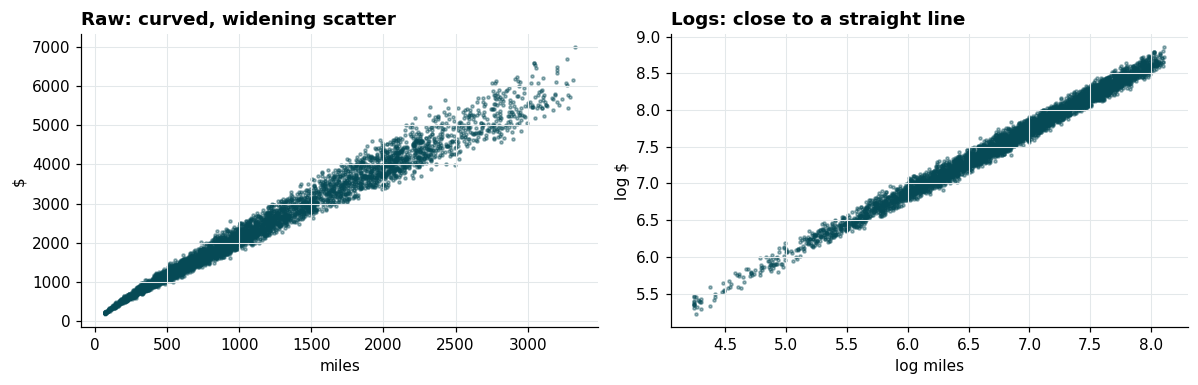

In [3]:
# Forward split: fit on Jan-Aug, evaluate on Sep-Oct (trustworthy rows). Plain least squares, so differences come from the feature only.
fit_m = (tr.date.dt.month <= 8).to_numpy() & trusted
test_m = (tr.date.dt.month > 8).to_numpy() & trusted
y = np.log(tr.posted_rate.to_numpy()); d = tr.distance.to_numpy(); ld = np.log(d)
variants = {"distance": [d], "distance + distance^2": [d, d ** 2], "log distance": [ld], "log distance + log distance^2": [ld, ld ** 2]}
rows = []
for name, cols in variants.items():
    X = np.column_stack([np.ones(len(y)), *cols])
    b = np.linalg.lstsq(X[fit_m], y[fit_m], rcond=None)[0]
    p = np.exp(X[test_m] @ b); a = tr.posted_rate.to_numpy()[test_m]
    rows.append({"distance representation": name, "test MAPE %": 100 * np.mean(np.abs(p - a) / a), "test MAE $": np.mean(np.abs(p - a))})
display(pd.DataFrame(rows).set_index("distance representation"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
s = tr[trusted].sample(5000, random_state=0)
axes[0].scatter(s.distance, s.posted_rate, s=4, alpha=0.4, color=TEAL); axes[0].set_title("Raw: curved, widening scatter"); axes[0].set_xlabel("miles"); axes[0].set_ylabel("$")
axes[1].scatter(np.log(s.distance), np.log(s.posted_rate), s=4, alpha=0.4, color=TEAL); axes[1].set_title("Logs: close to a straight line"); axes[1].set_xlabel("log miles"); axes[1].set_ylabel("log $")
fig.tight_layout(); save_fig(fig, P, "distance_transform"); plt.show()

**Result and decision.** Working in logs is what matters; the squared term is a cheap extra that changes little (as in notebook 1). Both are kept in the linear part (`log_distance`, `log_distance^2`). **Prediction time:** known for every load. **Leakage:** none. **Generalisation:** purely numeric, so unseen cities and future dates are unaffected. (`distance` itself also goes to the trees as `log_distance`.)

## 3. [Production] Equipment encoding

**Question.** How should a three-level category enter a linear part and a tree model?

**Why it matters.** Wrong encodings either impose a false order on a linear model or waste tree splits.

In [4]:
print("tree code:", EQUIPMENT_CODE)
display(pd.DataFrame({"flatbed": (tr.equipment == "Flatbed").astype(int), "reefer": (tr.equipment == "Reefer").astype(int), "equipment": tr.equipment}).drop_duplicates().sort_values("equipment").reset_index(drop=True))
m_lin = FreightRateModel(dmi, use_gbm=False).fit(train)
names = ["log_distance", "log_distance^2", "flatbed", "reefer", "daily_market_index", "trend/100d", "quarter_end_ramp"]
coef = pd.Series(m_lin.linear_.coef_ / m_lin.sd_, index=names)
display(Markdown(f"estimated premium over Dry Van (linear part, in price terms): **Flatbed {np.expm1(coef.flatbed):+.1%}**, **Reefer {np.expm1(coef.reefer):+.1%}**"))

tree code: {'Dry Van': 0, 'Flatbed': 1, 'Reefer': 2}


,flatbed,reefer,equipment
0,0,0,Dry Van
1,1,0,Flatbed
2,0,1,Reefer


estimated premium over Dry Van (linear part, in price terms): **Flatbed +8.3%**, **Reefer +12.9%**

**Why / how.** Reefer (refrigerated) and Flatbed equipment are costlier to supply. For the **linear** part, two 0/1 indicators (Dry Van is the baseline) avoid imposing an order; for the **trees**, a simple integer code is enough because trees can split anywhere. Available at prediction time: yes. Leakage: none. Generalisation: all three types occur in every period.

## 4. [Exploratory] Weight features

**Question.** Does weight matter, in what shape, and does the 47,500 cap or missingness carry information?

**Why it matters.** A feature with a tiny effect should not complicate the pipeline; a non-linear effect needs a flexible model.

,mean leftover (log),count
weight,,
"(-0.001, 15000.0]",-0.0451,1012
"(15000.0, 22000.0]",-0.0382,4704
"(22000.0, 28000.0]",-0.0242,10178
"(28000.0, 34000.0]",0.0010,13215
"(34000.0, 40000.0]",0.0215,10908
"(40000.0, 44000.0]",0.0306,4051
"(44000.0, 47499.0]",0.0335,1770
"(47499.0, 47500.0]",0.0334,1188


missing weight: mean leftover **+0.0007** (n=297); at the cap: **+0.0334** (n=1188); overall leftover sd: **0.0401**

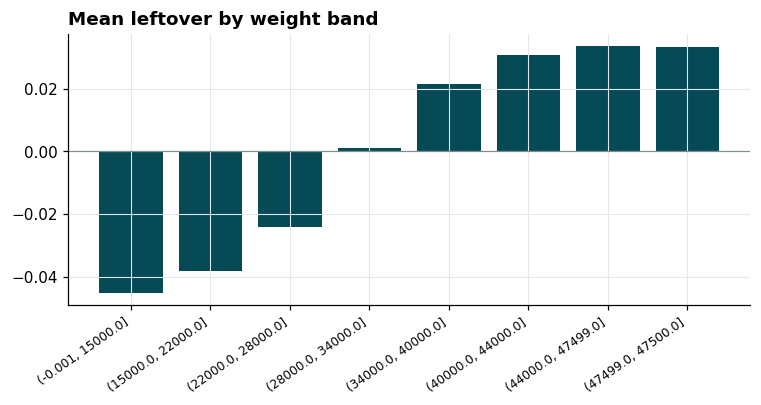

In [5]:
# leftover of the linear model (distance, equipment, market, trend, ramp) - does weight explain any of it?
lin_resid = np.log(tr.posted_rate) - np.log(m_lin.predict(tr))
w = tr.weight
bins = pd.cut(w, [0, 15000, 22000, 28000, 34000, 40000, 44000, 47499, 47500], include_lowest=True)
tab = lin_resid[trusted].groupby(bins[trusted], observed=True).agg(["mean", "count"])
tab = tab.rename(columns={"mean": "mean leftover (log)"}); display(tab.round(4))
display(Markdown(f"missing weight: mean leftover **{lin_resid[trusted & w.isna()].mean():+.4f}** (n={int((trusted & w.isna()).sum())}); "
                 f"at the cap: **{lin_resid[trusted & (w == 47500)].mean():+.4f}** (n={int((trusted & (w == 47500)).sum())}); "
                 f"overall leftover sd: **{lin_resid[trusted].std():.4f}**"))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(tab)), tab["mean leftover (log)"], color=TEAL); ax.axhline(0, color=GREY, lw=0.8)
ax.set_xticks(range(len(tab)), [str(i) for i in tab.index], rotation=35, ha="right", fontsize=8); ax.set_title("Mean leftover by weight band")
save_fig(fig, P, "weight_effect"); plt.show()

**Result and decision.** Weight is a **substantial, monotonic and saturating** effect, not a minor one: relative to what distance, equipment and the market explain, the lightest loads (under 15,000 lb) are priced about 4-5% *below* expectation and the heaviest (over 40,000 lb) about 3% *above*, flattening towards the cap. That is as large as the row-level noise (sd about 4% for this simple model), so weight is the **second most useful input after distance**. It is passed as `abs(weight)` to the **trees**, which capture the saturating shape, with `NaN` left as `NaN`. Rows at the cap sit on the same plateau as the 44,000-47,499 band (no extra effect), and rows with missing weight have an average leftover (about zero), consistent with missingness being unrelated to price. No separate "is capped" or "is missing" flags are added. **Prediction time:** yes. **Leakage:** none. **Generalisation:** unaffected by cities or dates.

## 5. [Exploratory] Pickup and delivery coordinates

**Question.** Is there a regional price pattern, and can coordinates capture it for cities the model has never seen?

**Why it matters.** City names cannot generalise to the 8 unseen validation cities; numeric location can.

sd of city-level mean leftover: pickup **0.0177**, delivery **0.0177** (versus row-level leftover sd 0.0401)

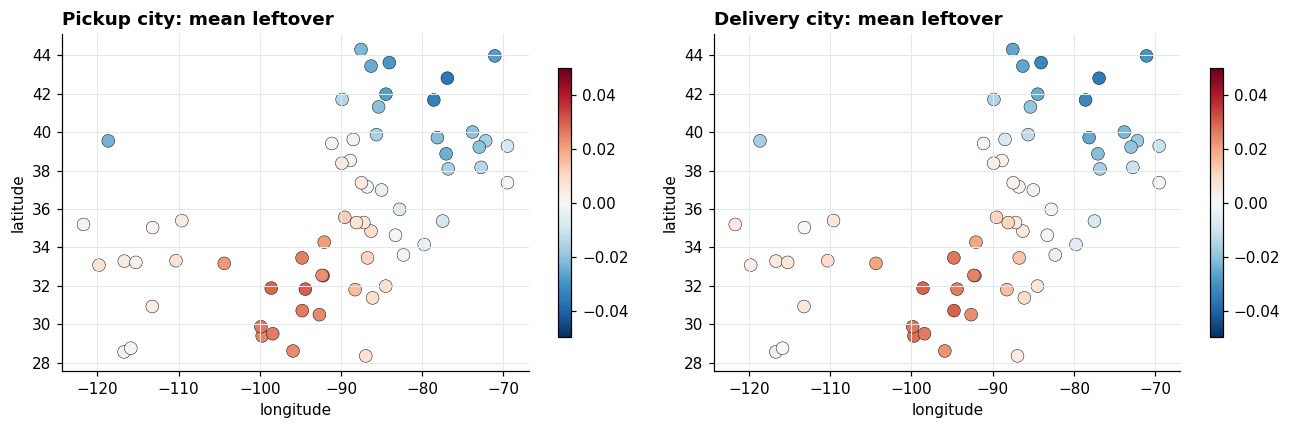

unseen cities inside the training coordinate box: **7 of 8**; outside: **['Laredo']**

,lat,lon
Laredo,25.5000,-97.2268
min,28.3576,-121.6985
max,44.3030,-69.5000


In [6]:
t = tr.assign(res=lin_resid)[trusted]
pk = t.groupby("pickup").agg(lat=("pickup_lat", "first"), lon=("pickup_lon", "first"), effect=("res", "mean"), n=("res", "size"))
dl = t.groupby("delivery").agg(lat=("delivery_lat", "first"), lon=("delivery_lon", "first"), effect=("res", "mean"), n=("res", "size"))
display(Markdown(f"sd of city-level mean leftover: pickup **{pk.effect.std():.4f}**, delivery **{dl.effect.std():.4f}** (versus row-level leftover sd {t.res.std():.4f})"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, df, title in [(axes[0], pk, "Pickup city: mean leftover"), (axes[1], dl, "Delivery city: mean leftover")]:
    sc = ax.scatter(df.lon, df.lat, c=df.effect, cmap="RdBu_r", vmin=-0.05, vmax=0.05, s=70, edgecolor="k", linewidth=0.3)
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); fig.colorbar(sc, ax=ax, shrink=0.8)
fig.tight_layout(); save_fig(fig, P, "regional_effects"); plt.show()

# do the unseen cities lie inside the coordinate range the model has seen?
seen = set(train.pickup) | set(train.delivery)
allc = pd.concat([valid[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1), valid[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)]).drop_duplicates()
trc = pd.concat([train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1), train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)]).drop_duplicates()
new = allc[~allc.city.isin(seen)]
inside = new.lat.between(trc.lat.min(), trc.lat.max()) & new.lon.between(trc.lon.min(), trc.lon.max())
display(Markdown(f"unseen cities inside the training coordinate box: **{int(inside.sum())} of {len(new)}**; outside: **{list(new.city[~inside])}**"))
display(pd.concat([new.set_index("city").loc[list(new.city[~inside])], trc[["lat", "lon"]].agg(["min", "max"])]))

**Result and decision.** Region matters, but modestly (city-level effects of roughly +/-2%): the map shows geographic structure rather than random scatter. The four coordinate columns go to the trees, which can learn smooth regional effects, and seven of the eight unseen cities lie inside the coordinate range the model was trained on. The exception (shown above, the table lists its coordinates beside the training min/max) falls just outside the training range; tree models treat such a value like the nearest boundary, which is a mild, disclosed extrapolation for about 1.6% of validation rows (195 loads touching Laredo). **Prediction time:** yes. **Leakage:** none. **Generalisation:** designed for unseen cities (tested by simulation in notebook 3). *Caveat:* the coordinates look approximate, so they work as region indicators; and a city-level effect estimated from few rows is noisy, which is another reason not to use city identities.

## 6. [Production] Daily market index

**Question.** How should `market_index` enter the model, and is it legitimately available for validation/December?

**Why it matters.** It is the strongest time-varying driver, but a careless construction could leak or add noise.

In [7]:
import inspect
print(inspect.getsource(daily_market_index))
rowdev = (tr.market_index - tr.date.map(dmi))
t = pd.DataFrame({"res": lin_resid, "row_dev": rowdev})[trusted & rowdev.notna()]
slope = np.polyfit(t.row_dev, t.res, 1)[0]
r = np.corrcoef(t.row_dev, t.res)[0, 1]
display(Markdown(f"Does the *row-level deviation* from the day's mean carry signal? slope = **{slope:+.4f}**, correlation = **{r:+.3f}** (compare the daily-level coefficient **{coef.daily_market_index:+.3f}**)"))
display(Markdown(f"days in the combined calendar: **{len(dmi)}**; rows per day min/median/max: "
                 f"**{pd.concat([train, valid]).groupby('date').size().min()} / {int(pd.concat([train, valid]).groupby('date').size().median())} / {pd.concat([train, valid]).groupby('date').size().max()}**"))

def daily_market_index(*frames: pd.DataFrame) -> pd.Series:
    """One market_index value per calendar day.

    The row-level market_index is the *same* daily level plus noise (sd ~0.025 per
    row, ~150-200 rows per day).  Averaging over a day gives the clean level.
    Only FEATURES are used here (no labels), so it is legal to average over
    train + validation together - that is how we get a value for Nov/Dec.
    """
    all_rows = pd.concat([f[["date", "market_index"]] for f in frames])
    return all_rows.groupby("date")["market_index"].mean().rename("daily_market_index")



Does the *row-level deviation* from the day's mean carry signal? slope = **+0.1359**, correlation = **+0.085** (compare the daily-level coefficient **+0.142**)

days in the combined calendar: **365**; rows per day min/median/max: **115 / 161 / 227**

**Why / how.** The row-level value is the day's level plus noise (notebook 1). Its deviation from the daily mean is **not** pure noise: the slope of the leftover on that deviation is about the same as the daily-level coefficient, and the correlation is small but statistically detectable (about +0.09 on 47,000 rows) only because the deviations are tiny (sd about 0.025, i.e. a price effect of roughly +/-0.35%). So the **daily mean captures the bulk of the market signal, but not all of it**; a row-level refinement is a possible small improvement and is tested as an ablation in notebook 3 rather than silently added. The daily mean remains the production feature because it is clean, always defined (even when a row's value is missing) and is the simplest statement of "market level that day".

**Is it legitimate at prediction time? - an honest answer.** The daily mean is computed from the **features** (not labels) of rows in `train_test.csv` *and* `validation.csv`. Using unlabelled test features is called *transductive* use. It is permitted here because the assessment *provides* those rows with their `market_index` and the task asks only for predictions of those same rows. It would **not** be available in a live system that must forecast a price before the day's market data exists: there you would need a *forecast* of the index, and accuracy would drop (this is measured in notebook 3, section 6). Also note it needs that day's rows: December dates have 163 or more validation rows each, so the estimate is stable.

## 7. [Production] Temporal drift

**Question.** Is there a slow upward movement in price that the other features do not explain, and how is it encoded?

**Why it matters.** A drift that is ignored becomes a systematic under-prediction in the future; one that is encoded wrongly can extrapolate dangerously.

In [8]:
days = (tr.date - T0).dt.days
vdays = (valid.date - T0).dt.days
display(pd.DataFrame({"min day": [days.min(), vdays.min()], "max day": [days.max(), vdays.max()]}, index=["train", "validation"]))
display(Markdown(f"trend coefficient (log-price per 100 days): **{coef['trend/100d']:+.4f}**  ->  over the 61 validation days this contributes about **{coef['trend/100d'] * 0.61:+.2%}** relative to the end of training (range of the term: 0 to {days.max()/100:.2f} in training, up to {vdays.max()/100:.2f} in validation)"))

# coefficient stability: fit on expanding windows, using the same code path as the pipeline
rows = []
for last_month in (5, 6, 7, 8, 9, 10):
    m = FreightRateModel(dmi, use_gbm=False).fit(train[train.date.dt.month <= last_month])
    rows.append({"training data through month": last_month, "trend per 100 days": (m.linear_.coef_ / m.sd_)[5], "market index coef": (m.linear_.coef_ / m.sd_)[4], "ramp coef": (m.linear_.coef_ / m.sd_)[6]})
display(pd.DataFrame(rows).set_index("training data through month"))

,min day,max day
train,0,303
validation,304,364


trend coefficient (log-price per 100 days): **+0.0197**  ->  over the 61 validation days this contributes about **+1.20%** relative to the end of training (range of the term: 0 to 3.03 in training, up to 3.64 in validation)

,trend per 100 days,market index coef,ramp coef
training data through month,,,
5,0.0269,0.1215,0.0357
6,0.0278,0.1185,0.0362
7,0.0210,0.1376,0.0394
8,0.0178,0.1478,0.0404
9,0.0180,0.1461,0.0412
10,0.0197,0.1425,0.0389


**Result and decision.** Prices drift upward by about 2% per 100 days beyond what the market index explains. The term is **linear in days since 2025-01-01** so that it can extrapolate (trees cannot). The expanding-window table shows the estimate is **not perfectly stable**: it was about 2.7-2.8% per 100 days using data through May-June and about 1.8-2.0% with data through August-October, while the market-index and ramp coefficients stayed in a narrow band. A drifting estimate is a warning that the trend is partly absorbing other structure; this is one more reason to treat it as an assumption. **Prediction time:** it is a calendar quantity, always available. **Leakage:** none. **Future dates:** this *is* extrapolation by construction: every validation day is later than every training day, and the term runs up to 3.64 against a training maximum of 3.03.

**What we cannot claim.** With only ten months of a single year, a genuine linear drift cannot be distinguished from part of an annual seasonal cycle. Over the 61 validation days the term contributes only about +1.2% relative to the end of training, but it is an assumption, not a fact; its December impact is quantified in notebook 4.

## 8. [Production] Days until quarter end and the quarter-end ramp

**Question.** How is the end-of-quarter premium represented?

**Why it matters.** It must be a function of the calendar only and shaped like the empirical pattern from notebook 1 (a rise over about the last month, then a reset).

def days_to_quarter_end(dates: pd.Series) -> np.ndarray:
    quarter_end = dates.dt.to_period("Q").dt.end_time.dt.normalize()
    return (quarter_end - dates).dt.days.to_numpy()

:
        cols.append(np.clip(1.0 - days_to_quarter_end(df["date"]) / RAMP_DAYS, 0.0, 1.0))
    return np.column_stack(cols).astype(float)



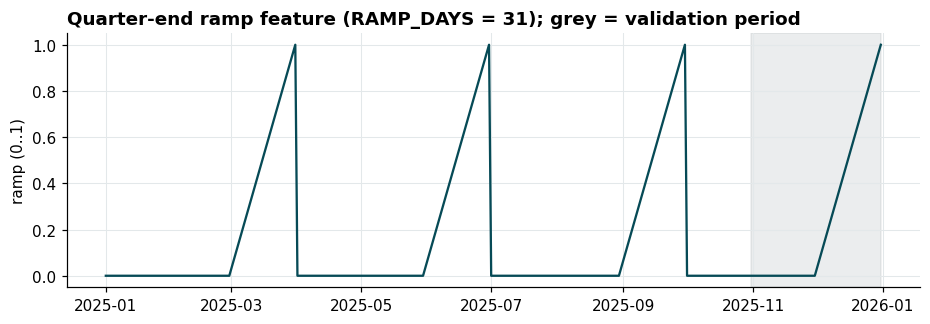

the ramp times its coefficient (**+0.0389**) = a premium of about **+4.0%** on the last day of a quarter, ~0 earlier than 31 days before quarter end

In [9]:
print(inspect.getsource(days_to_quarter_end)); print(inspect.getsource(linear_features).split("if use_ramp")[1][:140])
cal = pd.Series(pd.date_range("2025-01-01", "2025-12-31"))
ramp = np.clip(1 - days_to_quarter_end(cal) / RAMP_DAYS, 0, 1)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(cal, ramp, color=TEAL); ax.axvspan(train.date.max(), cal.max(), color=GREY, alpha=0.15)
ax.set_title(f"Quarter-end ramp feature (RAMP_DAYS = {RAMP_DAYS}); grey = validation period"); ax.set_ylabel("ramp (0..1)")
save_fig(fig, P, "ramp_feature"); plt.show()
display(Markdown(f"the ramp times its coefficient (**{coef.quarter_end_ramp:+.4f}**) = a premium of about **{np.expm1(coef.quarter_end_ramp):+.1%}** on the last day of a quarter, ~0 earlier than {RAMP_DAYS} days before quarter end"))

**Why / how.** Notebook 1 showed price rising by a few percent over the final weeks of March, June and September and resetting afterwards, but *not* in other month-ends. The feature is `clip(1 - days_to_quarter_end / 31, 0, 1)`: 0 until about a month before quarter-end, rising linearly to 1 on the last day, then 0 again. The ramp length (31 days) is tested in notebook 3.
**Prediction time:** pure calendar. **Leakage:** none. **Generalisation:** the evidence comes from **three quarter-ends**; none of the training data contain the end of Q4, so applying it to December is an **assumption** (see notebook 1, caveat 4, and notebook 4).

## 9. [Exploratory] Why `quote_signal` is excluded

**Question.** Would `quote_signal` (row-level or daily mean) be a safe feature?

**Why it matters.** A feature that looks predictive in-sample but is tied to the period it was observed in will fail on the future.

In [10]:
dq = pd.concat([train, valid]).groupby("date").quote_signal.mean()
t = pd.DataFrame({"res": lin_resid, "row_qs": tr.quote_signal, "daily_qs": tr.date.map(dq), "month": tr.date.dt.month})[trusted]
t["qs_dev"] = t.row_qs - t.daily_qs
rows = [{"candidate": "row-level quote_signal", "corr with leftover": t.res.corr(t.row_qs)},
        {"candidate": "daily mean quote_signal", "corr with leftover": t.res.corr(t.daily_qs)},
        {"candidate": "row deviation from daily mean", "corr with leftover": t.res.corr(t.qs_dev)}]
display(pd.DataFrame(rows).set_index("candidate"))
bym = t.groupby("month").apply(lambda g: g.res.corr(g.daily_qs), include_groups=False).rename("within-month corr (daily mean vs leftover)")
display(bym.to_frame().T)
display(Markdown(f"sign of the within-month correlation: positive in **{(bym > 0).sum()}** months, negative in **{(bym < 0).sum()}** months (a stable driver would have one sign)"))

,corr with leftover
candidate,
row-level quote_signal,0.0515
daily mean quote_signal,-0.0184
row deviation from daily mean,0.0667


month,1,2,3,4,5,6,7,8,9,10
within-month corr (daily mean vs leftover),-0.0195,-0.0109,-0.0139,-0.0265,0.0089,0.0143,-0.0561,-0.0087,0.0285,-0.0378


sign of the within-month correlation: positive in **3** months, negative in **7** months (a stable driver would have one sign)

**What the table shows.** Measured against the leftover of a model that **already contains the trend and the ramp**, the *daily* quote level has essentially no relation (correlation about -0.02; within-month correlations small and of mixed sign). Before the ramp was added (notebook 1) it correlated +0.68 with the leftover, so the daily level was largely a stand-in for the quarter-end calendar effect we now model directly. The *row-level deviation* from the daily mean is different: its correlation is small but positive (about +0.07, detectable at this sample size), i.e. there may be a genuine row-level quote effect that does not depend on the regime.

**Decision (and its cost).** The production model **excludes `quote_signal` entirely**. The daily level is excluded because it is a regime-dependent proxy; the row-level deviation is excluded to keep the model simple and because it is a weak effect, but **this has a measurable cost**, quantified honestly as an ablation in notebook 3. It is a judgement call, not a proven fact. **Prediction time:** available. **Leakage:** none. **Future dates:** the daily level is unstable; the row-level deviation is probably stable.

## 10. [Production] The final feature pipeline, with checks

**Question.** What do the two production feature matrices look like for train, validation and December, and can we prove no label or future information enters them?

**Why it matters.** This is the contract between data and model; every guarantee should be tested, not asserted.

In [11]:
dec_in = complete_december_inputs(december, train, valid)      # adds lat/lon (city lookup); the market index is supplied by dmi
sets = {"train": clean_inputs(train), "validation": clean_inputs(valid), "december": clean_inputs(dec_in)}
lin_names = ["log_distance", "log_distance^2", "flatbed", "reefer", "daily_market_index", "trend/100d", "quarter_end_ramp"]
lin = {k: pd.DataFrame(linear_features(v, dmi), columns=lin_names) for k, v in sets.items()}
tre = {k: tree_features(v) for k, v in sets.items()}

display(lin["validation"].head(3)); display(tre["validation"].head(3))
rng = pd.concat({k: v.agg(["min", "max"]).T for k, v in lin.items()}, axis=1)
display(rng)

,log_distance,log_distance^2,flatbed,reefer,daily_market_index,trend/100d,quarter_end_ramp
0,5.8033,33.6786,1.0000,0.0000,0.9018,3.0400,0.0000
1,7.7858,60.6187,0.0000,1.0000,0.9018,3.0400,0.0000
2,7.9539,63.2642,0.0000,0.0000,0.9018,3.0400,0.0000


,log_distance,equipment,weight,pickup_lat,pickup_lon,delivery_lat,delivery_lon
0,5.8033,1,"19,958.0000",30.5013,-92.6537,31.8044,-88.2519
1,7.7858,2,"34,114.0000",33.6097,-82.2999,28.5662,-116.7025
2,7.9539,0,"33,435.0000",35.1967,-121.6985,35.3738,-77.4761


train         validation         december        
                       min     max        min     max      min     max
log_distance        4.2485  8.1432     4.2485  8.1094   5.8861  5.8861
log_distance^2     18.0497 66.3112    18.0497 65.7629  34.6462 34.6462
flatbed             0.0000  1.0000     0.0000  1.0000   0.0000  0.0000
reefer              0.0000  1.0000     0.0000  1.0000   0.0000  0.0000
daily_market_index  0.7666  1.4016     0.8222  1.0445   0.8306  1.0445
trend/100d          0.0000  3.0300     3.0400  3.6400   3.3400  3.6400
quarter_end_ramp    0.0000  1.0000     0.0000  1.0000   0.0323  1.0000

In [12]:
# --- guarantees, each checked in code ---
checks = {
    "linear matrices contain no NaN": all(not v.isna().any().any() for v in lin.values()),
    "only 'weight' may be NaN in tree features": all(set(v.columns[v.isna().any()]) <= {"weight"} for v in tre.values()),
    "tree features contain no date / market / quote column": not ({"date", "market_index", "quote_signal", "posted_rate"} & set(tre["train"].columns)),
    "tree features have the same columns for train / validation / december": tre["train"].columns.equals(tre["validation"].columns) and tre["train"].columns.equals(tre["december"].columns),
    "features unchanged when the target is removed (no label used)": np.allclose(linear_features(clean_inputs(train.drop(columns="posted_rate")), dmi), linear_features(clean_inputs(train), dmi)),
    "december lat/lon found for both cities": bool(sets["december"][COORD_COLS].notna().all().all()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "a feature-pipeline guarantee failed"

# where does the validation period fall outside the training range of each linear feature?
outside = {c: float(((lin["validation"][c] < lin["train"][c].min()) | (lin["validation"][c] > lin["train"][c].max())).mean()) for c in lin_names}
display(pd.Series(outside, name="share of validation rows outside the training range").to_frame().style.format("{:.1%}"))

,passed
linear matrices contain no NaN,True
only 'weight' may be NaN in tree features,True
tree features contain no date / market / quote column,True
tree features have the same columns for train / validation / december,True
features unchanged when the target is removed (no label used),True
december lat/lon found for both cities,True


,share of validation rows outside the training range
log_distance,0.0%
log_distance^2,0.0%
flatbed,0.0%
reefer,0.0%
daily_market_index,0.0%
trend/100d,100.0%
quarter_end_ramp,0.0%


**Interpretation.** All guarantees pass. The ranges show exactly where the model **extrapolates**: only `trend/100d` leaves the training range for validation rows (by construction: every validation day is later than every training day), and for December rows the market index and ramp stay inside training ranges (the ramp's *meaning* in Q4 is the untested part, not its numeric range). Distance, equipment, weight and coordinates stay inside their training ranges.

## Conclusion

* Seven linear and six tree inputs are built by **`common.py`**; this notebook only demonstrates and tests them. No second implementation exists.
* The **numeric** choices (log distance, daily-mean index) are well supported. The **temporal** choices (drift, quarter-end ramp) are supported in-sample but remain assumptions for Nov-Dec: they are isolated in the linear part so that they can be inspected, ablated and, if needed, switched off (`use_trend`, `use_ramp`).
* `quote_signal` and the row-level market-index deviation are deliberately excluded from production; their ablations (with measured cost) are in notebook 3.

**Next:** `03_model_development_and_validation.ipynb` tests these choices rigorously.